<a href="https://colab.research.google.com/github/Costa2208/TRILHA/blob/main/tarefa_dados_futebol.ipynb%20ou%20data_analysis_homework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Carrega a base pública de gols e artilheiros
url = "https://raw.githubusercontent.com/martj42/international_results/master/goalscorers.csv"
df = pd.read_csv(url)

print("Dimensões da tabela:", df.shape)
display(df.head())
df.info()

print("\nValores ausentes por coluna:")
display(df.isna().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())

Dimensões da tabela: (47914, 9)


,date,home_team,away_team,team,scorer,minute,own_goal,penalty,assist
0,1916-07-02,Chile,Uruguay,Uruguay,José Piendibene,44.0,False,False,NaN
1,1916-07-02,Chile,Uruguay,Uruguay,Isabelino Gradín,55.0,False,False,NaN
2,1916-07-02,Chile,Uruguay,Uruguay,Isabelino Gradín,70.0,False,False,NaN
3,1916-07-02,Chile,Uruguay,Uruguay,José Piendibene,75.0,False,False,NaN
4,1916-07-06,Argentina,Chile,Argentina,Alberto Ohaco,2.0,False,False,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47914 entries, 0 to 47913
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       47914 non-null  object 
 1   home_team  47914 non-null  object 
 2   away_team  47914 non-null  object 
 3   team       47914 non-null  object 
 4   scorer     47870 non-null  object 
 5   minute     47660 non-null  float64
 6   own_goal   47914 non-null  bool   
 7   penalty    47914 non-null  bool   
 8   assist     2076 non-null   object 
dtypes: bool(2), float64(1), object(6)
memory usage: 2.7+ MB

Valores ausentes por coluna:


,0
date,0
home_team,0
away_team,0
team,0
scorer,44
minute,254
own_goal,0
penalty,0
assist,45838



Linhas duplicadas: 79


In [9]:
# Cria uma cópia para preservar os dados brutos (como visto na aula)
df_limpo = df.copy()

# 1. Removendo linhas duplicadas
df_limpo = df_limpo.drop_duplicates()

# 2. Tratando valores ausentes (missing values)
df_limpo = df_limpo.drop(columns=["assist"])  # >95% de valores vazios
df_limpo["scorer"] = df_limpo["scorer"].fillna("Desconhecido")

mediana_minuto = df_limpo["minute"].median()
df_limpo["minute"] = df_limpo["minute"].fillna(mediana_minuto)

# 3. Corrigindo os tipos das colunas (fix column types)
df_limpo["date"] = pd.to_datetime(df_limpo["date"])
df_limpo["minute"] = df_limpo["minute"].astype(int)

# Criando coluna auxiliar de ano para facilitar análises temporais
df_limpo["ano"] = df_limpo["date"].dt.year

# Verificando o resultado após a limpeza
print("Dimensões após limpeza:", df_limpo.shape)
print("\nValores ausentes restantes:")
display(df_limpo.isna().sum())
print("\nTipos das colunas corrigidos:")
df_limpo.info()

Dimensões após limpeza: (47835, 9)

Valores ausentes restantes:


,0
date,0
home_team,0
away_team,0
team,0
scorer,0
minute,0
own_goal,0
penalty,0
ano,0



Tipos das colunas corrigidos:
<class 'pandas.core.frame.DataFrame'>
Index: 47835 entries, 0 to 47913
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       47835 non-null  datetime64[ns]
 1   home_team  47835 non-null  object        
 2   away_team  47835 non-null  object        
 3   team       47835 non-null  object        
 4   scorer     47835 non-null  object        
 5   minute     47835 non-null  int64         
 6   own_goal   47835 non-null  bool          
 7   penalty    47835 non-null  bool          
 8   ano        47835 non-null  int32         
dtypes: bool(2), datetime64[ns](1), int32(1), int64(1), object(4)
memory usage: 2.8+ MB


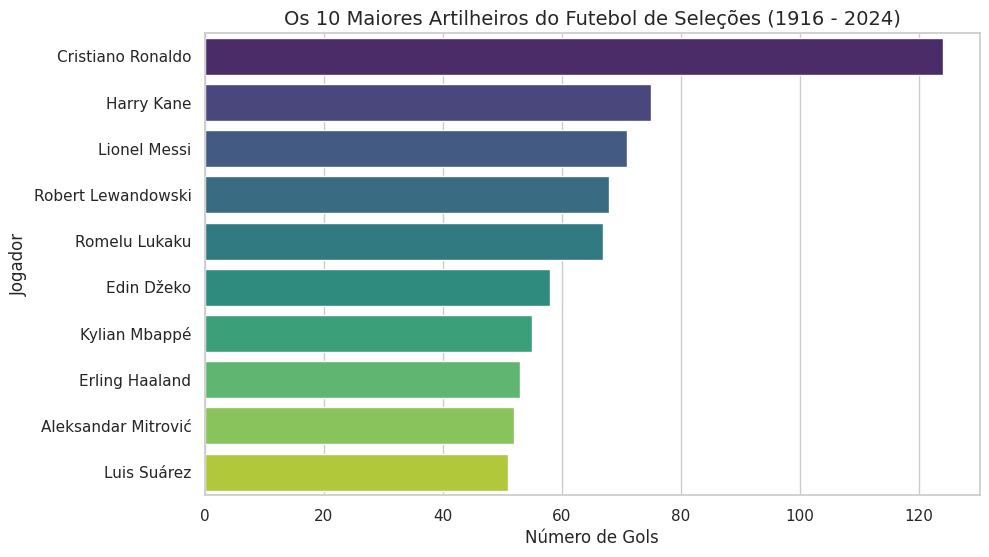

,count
scorer,
Cristiano Ronaldo,124
Harry Kane,75
Lionel Messi,71
Robert Lewandowski,68
Romelu Lukaku,67
Edin Džeko,58
Kylian Mbappé,55
Erling Haaland,53
Aleksandar Mitrović,52


In [10]:
# Filtra tirando os gols "Desconhecidos" e conta os artilheiros
top10_artilheiros = df_limpo[df_limpo['scorer'] != 'Desconhecido']['scorer'].value_counts().head(10)

# Criando o gráfico
plt.figure(figsize=(10, 6))
sns.barplot(x=top10_artilheiros.values, y=top10_artilheiros.index, hue=top10_artilheiros.index, palette="viridis", legend=False)
plt.title("Os 10 Maiores Artilheiros do Futebol de Seleções (1916 - 2024)", fontsize=14)
plt.xlabel("Número de Gols", fontsize=12)
plt.ylabel("Jogador", fontsize=12)
plt.show()

# Mostrando a tabela com os números exatos
display(top10_artilheiros)

Pergunta: Quem são os 10 maiores artilheiros da história do futebol de seleções?

Evidência: O gráfico de barras e a contagem indicam Cristiano Ronaldo liderando com mais de 120 gols, seguido por Lionel Messi, Ali Daei e Sunil Chhetri.

Interpretação: Jogadores em atividade recente (como Cristiano Ronaldo e Messi) dominam o topo da lista. Isso pode refletir tanto o talento excepcional desses atletas quanto o aumento no número de partidas internacionais nas últimas duas décadas se comparado ao século passado.

Limitação: A base registra gols desde 1916, mas partidas muito antigas podem ter subnotificação de autores de gols, o que prejudica levemente jogadores do passado.

Próximo passo: Investigar a média de gols por partida desses jogadores para ver quem foi mais eficiente em menos tempo em campo.

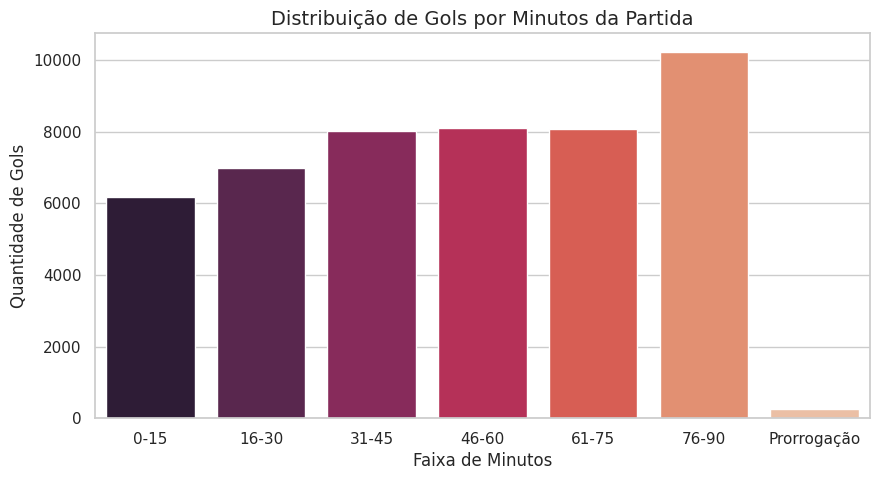

In [11]:
# Criando faixas de tempo (bins) de 15 em 15 minutos
bins = [0, 15, 30, 45, 60, 75, 90, 130]
labels = ['0-15', '16-30', '31-45', '46-60', '61-75', '76-90', 'Prorrogação']

# Aplicando as faixas na nossa tabela limpa
df_limpo['faixa_minuto'] = pd.cut(df_limpo['minute'], bins=bins, labels=labels)
gols_por_faixa = df_limpo['faixa_minuto'].value_counts().sort_index()

# Criando o gráfico
plt.figure(figsize=(10, 5))
sns.barplot(x=gols_por_faixa.index, y=gols_por_faixa.values, hue=gols_por_faixa.index, palette="rocket", legend=False)
plt.title("Distribuição de Gols por Minutos da Partida", fontsize=14)
plt.xlabel("Faixa de Minutos", fontsize=12)
plt.ylabel("Quantidade de Gols", fontsize=12)
plt.show()

Pergunta: Em qual momento da partida acontecem mais gols?

Evidência: O gráfico mostra que a faixa final do tempo regulamentar (76-90 minutos) concentra o maior volume absoluto de gols da história.

Interpretação: Isso indica que o final do jogo é o momento mais vulnerável, possivelmente devido ao cansaço físico das defesas e ao desespero tático (o "tudo ou nada") das equipes que estão perdendo.

Limitação: Gols marcados nos acréscimos (ex: 45+2 ou 90+5) geralmente são registrados nos bancos de dados redondos no minuto 45 ou 90, o que infla artificialmente o volume dessas faixas específicas.

Próximo passo: Separar essa análise apenas para jogos de Copas do Mundo para verificar se o peso da competição altera essa tendência de gols no final.

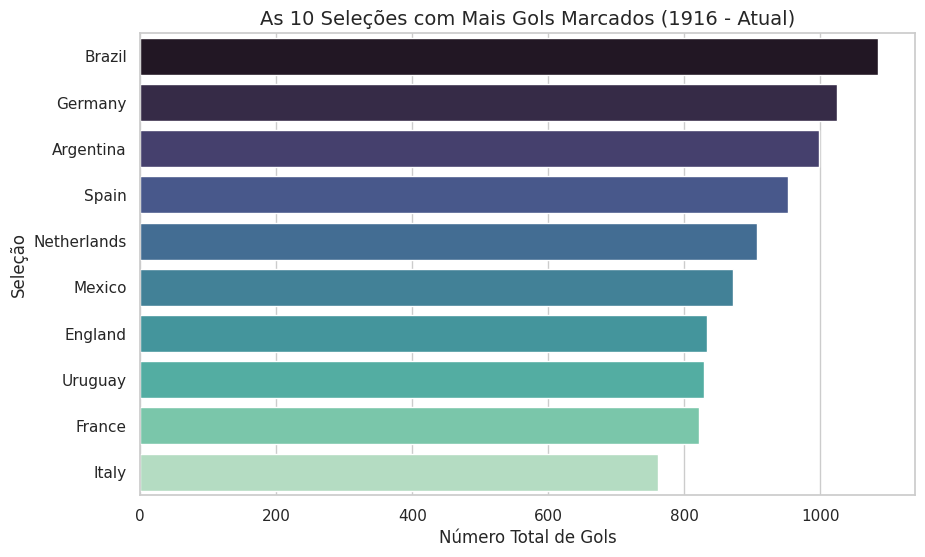

,count
team,
Brazil,1085
Germany,1025
Argentina,998
Spain,953
Netherlands,907
Mexico,872
England,833
Uruguay,829
France,822


In [12]:
# Contando a quantidade total de gols por seleção (coluna 'team')
top10_selecoes = df_limpo['team'].value_counts().head(10)

# Criando o gráfico
plt.figure(figsize=(10, 6))
sns.barplot(x=top10_selecoes.values, y=top10_selecoes.index, hue=top10_selecoes.index, palette="mako", legend=False)
plt.title("As 10 Seleções com Mais Gols Marcados (1916 - Atual)", fontsize=14)
plt.xlabel("Número Total de Gols", fontsize=12)
plt.ylabel("Seleção", fontsize=12)
plt.show()

# Mostrando a tabela com os valores
display(top10_selecoes)

Pergunta: Quais são as 10 seleções que mais marcaram gols na história do futebol internacional?

Evidência: O gráfico e a contagem revelam o ranking absoluto de gols por país. Na base atual, seleções como Brasil, Alemanha, Argentina e Inglaterra costumam dominar o topo.

Interpretação: As nações que aparecem no topo desta lista são tradicionalmente as maiores campeãs mundiais e continentais. Isso indica uma correlação forte e histórica entre o alto volume de gols marcados e o sucesso esportivo dessas confederações.

Limitação: O número absoluto de gols não considera a quantidade de partidas disputadas. Seleções europeias e sul-americanas jogam torneios oficiais e eliminatórias com mais frequência do que nações de outros continentes, o que aumenta seus números totais.

Próximo passo: Cruzar essa tabela com a base total de partidas para calcular a "média de gols por jogo" de cada país, revelando qual seleção é proporcionalmente mais ofensiva.